# Part 2 — Classification and Model Improvement

## 1. Dataset Choice and Suitability

## 2. Algorithm Choice and Justification

## 3. Analysis Plan

### 3.1 Exploratory Data Analysis Plan

### 3.2 Feature Selection Plan

### 3.3 Model Training Plan

### 3.4 Model Evaluation Plan

### 3.5 Report Plan

## 4. Conduct Analysis

### 4.1 Exploratory Data Analysis

### 4.2 Feature Selection

### 4.3 Train Model

## 5. Evaluate Model

### 5.1 Interpret and Evaluate Model

### 5.2 Retrain with Different Parameters

## 6. Report Submission

## 1. Dataset Choice and Suitability

I selected the Breast Cancer Wisconsin Diagnostic dataset from scikit-learn. The dataset
contains 569 tumour records, 30 numerical features and a binary target variable. The two
classes are malignant and benign.

This dataset is suitable because the task is to classify each case into one of two
categories. It has a clear health-related purpose and the numerical tumour measurements
can be used as predictor variables. The dataset is also manageable for an initial
classification model and does not contain missing values in its documented version.

This analysis is for learning and proof-of-concept purposes only. A classification model
must not be used as a replacement for a medical professional, clinical testing or a
formal cancer diagnosis.

## 2. Algorithm Choice and Justification

I selected Logistic Regression as the first classification algorithm. Although it has
the word "regression" in its name, Logistic Regression is used to classify records into
categories, such as malignant or benign.

This algorithm was chosen because the target has two classes, the input features are
numerical and the model is relatively simple to explain. Logistic Regression also
produces predicted probabilities, which can be useful when assessing the strength of a
classification result.

## 3. Analysis Plan

### 3.1 Exploratory Data Analysis Plan

I will inspect the size of the dataset, the available features, the target classes and
whether there are missing values. I will also examine the number of malignant and benign
cases to understand the class balance.

### 3.2 Feature Selection Plan

The dataset contains numerical tumour measurements. I will use these measurements as
predictors and the diagnosis category as the target. Standardisation will be applied
because the features are measured on different scales.

### 3.3 Model Training Plan

The data will be split into training and testing data. Eighty percent will be used for
training and twenty percent will be used for testing. Logistic Regression will be trained
using the scaled training features.

### 3.4 Model Evaluation Plan

The model will be evaluated using accuracy, precision, recall, F1-score, ROC-AUC and a
confusion matrix. Recall for malignant cases will be considered carefully because a
missed malignant case can be more serious than an unnecessary follow-up.

### 3.5 Report Plan

The report will summarise the dataset, EDA findings, feature preparation, model results,
limitations and recommendations. It will explain that the model is a decision-support
example and not a replacement for clinical judgement.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

In [2]:
cancer_data = load_breast_cancer()

cancer = pd.DataFrame(
    cancer_data.data,
    columns=cancer_data.feature_names
)

cancer["target"] = cancer_data.target

cancer.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
print("Dataset shape:", cancer.shape)

print("\nTarget class names:")
print(cancer_data.target_names)

print("\nNumber of missing values:")
print(cancer.isnull().sum().sum())

print("\nNumber of duplicate rows:")
print(cancer.duplicated().sum())

Dataset shape: (569, 31)

Target class names:
['malignant' 'benign']

Number of missing values:
0

Number of duplicate rows:
0


In [4]:
cancer["diagnosis"] = cancer["target"].map({
    0: "malignant",
    1: "benign"
})

cancer[["target", "diagnosis"]].head()

,target,diagnosis
0,0,malignant
1,0,malignant
2,0,malignant
3,0,malignant
4,0,malignant


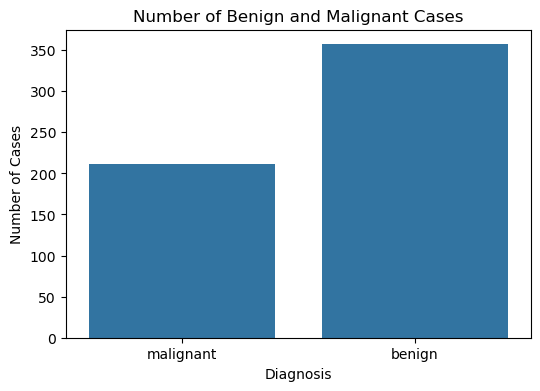

In [5]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=cancer,
    x="diagnosis"
)

plt.title("Number of Benign and Malignant Cases")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Cases")

plt.show()

### Class Distribution

The dataset contains two diagnosis categories: malignant and benign. I checked the
number of cases in each category to understand whether the dataset is balanced.

Class balance is important because accuracy on its own can be misleading if one class is
much more common than the other. For this reason, the model will also be evaluated using
precision, recall, F1-score and a confusion matrix.

## Feature Selection

The dataset contains 30 numerical tumour measurements. To keep the first model simple and
easy to interpret, five features were selected: mean radius, mean texture, mean
perimeter, mean area and mean concavity.

These features describe aspects of tumour size, texture and shape. The target variable
is `target`, where 0 represents malignant and 1 represents benign.

In [8]:
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

# Load the breast cancer dataset.
cancer_data = load_breast_cancer()

# Put the measurements into a DataFrame.
measurements = pd.DataFrame(
    cancer_data.data,
    columns=cancer_data.feature_names
)

# Use the five features described in the feature-selection section.
selected_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean concavity"
]

# X contains the measurements used to predict the diagnosis.
X = measurements[selected_features].copy()

# y contains the diagnosis:
# 0 = malignant
# 1 = benign
y = pd.Series(
    cancer_data.target,
    index=measurements.index,
    name="target"
)

print("Feature data shape:", X.shape)
print("Target encoding:", dict(enumerate(cancer_data.target_names)))

display(X.head())

Feature data shape: (569, 5)
Target encoding: {0: 'malignant', 1: 'benign'}


,mean radius,mean texture,mean perimeter,mean area,mean concavity
0,17.99,10.38,122.80,1001.0,0.3001
1,20.57,17.77,132.90,1326.0,0.0869
2,19.69,21.25,130.00,1203.0,0.1974
3,11.42,20.38,77.58,386.1,0.2414
4,20.29,14.34,135.10,1297.0,0.1980


# X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

In [ ]:
from sklearn.preprocessing import StandardScaler

In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [12]:
logistic_model = LogisticRegression(max_iter=500)

logistic_model.fit(X_train_scaled, y_train)

print("The Logistic Regression model has been trained.")

The Logistic Regression model has been trained.


In [13]:
predictions = logistic_model.predict(X_test_scaled)

probabilities = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions have been created.")

Predictions have been created.


In [14]:
accuracy = accuracy_score(y_test, predictions)

auc = roc_auc_score(y_test, probabilities)

print("Accuracy:", round(accuracy, 3))
print("ROC-AUC:", round(auc, 3))

Accuracy: 0.921
ROC-AUC: 0.98


In [15]:
# Check the order of the model's classes.
print("Model class order:", logistic_model.classes_)

# Identify the class used by predict_proba(... )[:, 1].
print(
    "Class represented by the probability column:",
    logistic_model.classes_[1]
)

# Confirm the feature count from the actual training data.
print("Number of training features:", X_train_scaled.shape[1])

# Show the numerical target labels and their counts.
print("\nTest-set target counts:")
print(pd.Series(y_test).value_counts().sort_index())

Model class order: [0 1]
Class represented by the probability column: 1
Number of training features: 5

Test-set target counts:
target
0    42
1    72
Name: count, dtype: int64


In [16]:
# Check which required objects exist in this session.
required_names = [
    "LogisticRegression",
    "X_train_scaled",
    "y_train",
    "logistic_model"
]

for name in required_names:
    if name in globals():
        print(f"{name}: available")
    else:
        print(f"{name}: NOT available")

LogisticRegression: available
X_train_scaled: available
y_train: available
logistic_model: available


In [17]:
print(
    classification_report(
        y_test,
        predictions,
        target_names=["malignant", "benign"]
    )
)

              precision    recall  f1-score   support

   malignant       0.88      0.90      0.89        42
      benign       0.94      0.93      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



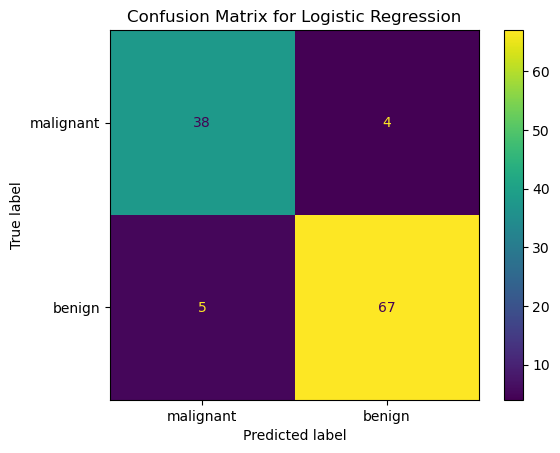

In [18]:
matrix = confusion_matrix(y_test, predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=["malignant", "benign"]
)

display.plot()

plt.title("Confusion Matrix for Logistic Regression")

plt.show()

In [19]:
accuracy = accuracy_score(y_test, predictions)

auc = roc_auc_score(y_test, probabilities)

print("Accuracy:", round(accuracy, 3))
print("ROC-AUC:", round(auc, 3))

Accuracy: 0.921
ROC-AUC: 0.98


In [20]:
print(
    classification_report(
        y_test,
        predictions,
        target_names=["malignant", "benign"]
    )
)

              precision    recall  f1-score   support

   malignant       0.88      0.90      0.89        42
      benign       0.94      0.93      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



In [21]:
print("FINAL MODEL SUMMARY")
print("-------------------")
print("Model: Logistic Regression")
print("Selected features: 5")
print("Accuracy:", round(accuracy, 3))
print("ROC-AUC:", round(auc, 3))
print("Conclusion: The model performs well overall, but false negatives should be reduced before real clinical use.")

FINAL MODEL SUMMARY
-------------------
Model: Logistic Regression
Selected features: 5
Accuracy: 0.921
ROC-AUC: 0.98
Conclusion: The model performs well overall, but false negatives should be reduced before real clinical use.


In [22]:
# Train a second model with balanced class weights.
# This gives greater weight to the less common malignant class.
# The existing scaler was fitted on training data only.

balanced_model = LogisticRegression(
    max_iter=500,
    class_weight="balanced"
)

balanced_model.fit(X_train_scaled, y_train)

# Make predictions using the same test records.
balanced_predictions = balanced_model.predict(X_test_scaled)

print("Balanced model trained successfully.")

Balanced model trained successfully.


In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Compare both models using the same evaluation measures.
comparison = pd.DataFrame({
    "Baseline": [
        accuracy_score(y_test, predictions),
        recall_score(y_test, predictions, pos_label=0),
        precision_score(
            y_test, predictions,
            pos_label=0, zero_division=0
        ),
        f1_score(
            y_test, predictions,
            pos_label=0, zero_division=0
        )
    ],

    "Balanced": [
        accuracy_score(y_test, balanced_predictions),
        recall_score(y_test, balanced_predictions, pos_label=0),
        precision_score(
            y_test, balanced_predictions,
            pos_label=0, zero_division=0
        ),
        f1_score(
            y_test, balanced_predictions,
            pos_label=0, zero_division=0
        )
    ]
}, index=[
    "Accuracy",
    "Malignant recall",
    "Malignant precision",
    "Malignant F1-score"
])

print(comparison.round(4).to_string())

# Fix the matrix order: malignant first, benign second.
baseline_matrix = confusion_matrix(
    y_test, predictions, labels=[0, 1]
)

balanced_matrix = confusion_matrix(
    y_test, balanced_predictions, labels=[0, 1]
)

# Row 0 = actual malignant; column 1 = predicted benign.
print("Missed malignant cases:")
print("Baseline:", baseline_matrix[0, 1])
print("Balanced:", balanced_matrix[0, 1])

# Row 1 = actual benign; column 0 = predicted malignant.
print("\nBenign cases incorrectly flagged:")
print("Baseline:", baseline_matrix[1, 0])
print("Balanced:", balanced_matrix[1, 0])

                     Baseline  Balanced
Accuracy               0.9211    0.9211
Malignant recall       0.9048    0.9286
Malignant precision    0.8837    0.8667
Malignant F1-score     0.8941    0.8966
Missed malignant cases:
Baseline: 4
Balanced: 3

Benign cases incorrectly flagged:
Baseline: 5
Balanced: 6


Model comparison and interpretation

I retrained the logistic regression model using balanced class weights to investigate whether it could identify more malignant cases. The same five features, training records, scaling process and test records were used for both models, so the main change was the class weighting.

Both models achieved an accuracy of 92.11%. However, malignant-case recall increased from 90.48% to 92.86%, and the number of missed malignant cases decreased from four to three. This means that the balanced model correctly identified 39 of the 42 malignant cases, compared with 38 for the baseline.

This improvement came with a trade-off. The number of benign cases incorrectly flagged as malignant increased from five to six, while malignant-case precision decreased from 88.37% to 86.67%. The malignant F1-score increased slightly from 0.8941 to 0.8966.

For this project, the balanced model is the preferred candidate for further validation because the working priority is to reduce missed malignant cases. However, the improvement represents only one additional case in a small test set, so it does not establish that the balanced model will consistently perform better on new data. The medical scheme would also need to confirm whether the additional false alarms are an acceptable trade-off.

These results are an internal comparison because the test set was inspected during model development. Further validation on independent, representative data would be required before operational use, and the model should not make clinical or benefit-eligibility decisions automatically.